In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

possible_paths = [
    Path("data/retail_store_inventory.csv"),
    Path("../data/retail_store_inventory.csv")
]

data_path = next((path for path in possible_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError("retail_store_inventory.csv not found in the data folder")

df = pd.read_csv(data_path)

print("RetailMind dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()



RetailMind dataset loaded successfully!
Dataset shape: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [3]:

# Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDATASET INFORMATION:")
df.info()

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())


COLUMN NAMES:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  str    
 1   Store ID            73100 non-null  str    
 2   Product ID          73100 non-null  str    
 3   Category            73100 non-null  str    
 4   Region              73100 non-null  str    
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11

In [4]:

# Summary of numerical columns
print("NUMERICAL SUMMARY:")
display(df.describe())

# Check negative values in important columns
columns_to_check = [
    'Inventory Level',
    'Units Sold',
    'Units Ordered',
    'Demand Forecast',
    'Price',
    'Discount',
    'Competitor Pricing'
]

print("\nNEGATIVE VALUES:")
for col in columns_to_check:
    print(col, ":", (df[col] < 0).sum())

# Check unique categories
print("\nPRODUCT CATEGORIES:")
print(df['Category'].value_counts())

print("\nREGIONS:")
print(df['Region'].value_counts())

print("\nSEASONALITY:")
print(df['Seasonality'].value_counts())
    

NUMERICAL SUMMARY:


,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000



NEGATIVE VALUES:
Inventory Level : 0
Units Sold : 0
Units Ordered : 0
Demand Forecast : 673
Price : 0
Discount : 0
Competitor Pricing : 0

PRODUCT CATEGORIES:
Category
Furniture      14699
Toys           14643
Clothing       14626
Groceries      14611
Electronics    14521
Name: count, dtype: int64

REGIONS:
Region
East     18349
South    18297
North    18228
West     18226
Name: count, dtype: int64

SEASONALITY:
Seasonality
Spring    18317
Summer    18305
Winter    18285
Autumn    18193
Name: count, dtype: int64


In [5]:

# Extract records with negative demand forecasts
negative_forecasts = df[df['Demand Forecast'] < 0]

print("Number of negative forecasts:", len(negative_forecasts))

print("\nNegative forecast statistics:")
print(negative_forecasts['Demand Forecast'].describe())

print("\nSample negative forecast records:")
display(negative_forecasts.head(10))

print("\nDate range of negative forecasts:")
print(negative_forecasts['Date'].min())
print(negative_forecasts['Date'].max())



Number of negative forecasts: 673

Negative forecast statistics:
count    673.000000
mean      -3.693730
std        2.535978
min       -9.990000
25%       -5.470000
50%       -3.380000
75%       -1.540000
max       -0.010000
Name: Demand Forecast, dtype: float64

Sample negative forecast records:


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
63,2022-01-01,S004,P0004,Groceries,West,437,0,160,-2.40,87.23,10,Sunny,0,90.36,Spring
141,2022-01-02,S003,P0002,Groceries,East,175,2,140,-3.40,87.50,0,Rainy,0,91.20,Autumn
278,2022-01-03,S004,P0019,Toys,North,140,1,47,-3.91,80.41,0,Snowy,0,76.90,Winter
511,2022-01-06,S001,P0012,Groceries,North,59,1,88,-8.37,63.21,0,Rainy,0,60.48,Spring
730,2022-01-08,S002,P0011,Electronics,South,64,7,79,-2.99,92.43,0,Snowy,0,88.55,Spring
844,2022-01-09,S003,P0005,Furniture,West,418,4,143,-1.33,60.22,0,Cloudy,1,58.63,Summer
1011,2022-01-11,S001,P0012,Toys,East,205,3,120,-6.05,38.97,20,Sunny,1,41.52,Winter
1107,2022-01-12,S001,P0008,Clothing,West,432,0,33,-3.55,55.07,0,Cloudy,0,51.15,Autumn
1149,2022-01-12,S003,P0010,Furniture,South,74,6,77,-0.11,34.77,15,Snowy,0,33.56,Summer
1180,2022-01-12,S005,P0001,Toys,South,132,6,84,-2.04,60.36,5,Rainy,1,59.95,Spring



Date range of negative forecasts:
2022-01-01
2024-01-01


In [6]:

# Convert Date from text into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Check date range
print("START DATE:", df['Date'].min())
print("END DATE:", df['Date'].max())

# Check number of unique stores and products
print("\nNUMBER OF STORES:", df['Store ID'].nunique())
print("NUMBER OF PRODUCTS:", df['Product ID'].nunique())

# Check records for each store
print("\nRECORDS PER STORE:")
print(df['Store ID'].value_counts())

# Check records for each product
print("\nNUMBER OF UNIQUE PRODUCT CATEGORIES:")
print(df['Category'].nunique())

# Check repeated date-store-product combinations
print("\nDUPLICATE DATE-STORE-PRODUCT RECORDS:")
print(df.duplicated(
    subset=['Date', 'Store ID', 'Product ID']
).sum())

# Sort records chronologically
df = df.sort_values(
    by=['Store ID', 'Product ID', 'Date']
).reset_index(drop=True)

print("\nDATE CONVERSION AND SORTING COMPLETED!")


START DATE: 2022-01-01 00:00:00
END DATE: 2024-01-01 00:00:00

NUMBER OF STORES: 5
NUMBER OF PRODUCTS: 20

RECORDS PER STORE:
Store ID
S001    14620
S002    14620
S003    14620
S004    14620
S005    14620
Name: count, dtype: int64

NUMBER OF UNIQUE PRODUCT CATEGORIES:
5

DUPLICATE DATE-STORE-PRODUCT RECORDS:
0

DATE CONVERSION AND SORTING COMPLETED!


In [7]:

# Create calendar features
df['Day'] = df['Date'].dt.day
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)

# Create historical sales features separately for each store-product pair
grouped = df.groupby(['Store ID', 'Product ID'])['Units Sold']

df['lag_1'] = grouped.shift(1)
df['lag_7'] = grouped.shift(7)
df['lag_14'] = grouped.shift(14)
df['lag_30'] = grouped.shift(30)

# Calculate averages using previous days only
df['rolling_mean_7'] = grouped.transform(
    lambda x: x.shift(1).rolling(window=7).mean()
)

df['rolling_mean_30'] = grouped.transform(
    lambda x: x.shift(1).rolling(window=30).mean()
)

# Remove rows without enough historical information
df = df.dropna().reset_index(drop=True)

print("FEATURE ENGINEERING COMPLETED!")
print("Updated dataset shape:", df.shape)

print("\nNEW FEATURES:")
print([
    'Day', 'Month', 'Year', 'DayOfWeek', 'IsWeekend',
    'lag_1', 'lag_7', 'lag_14', 'lag_30',
    'rolling_mean_7', 'rolling_mean_30'
])

display(df.head())


C:\Users\HP\AppData\Local\Temp\ipykernel_16788\356954823.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['DayOfWeek'] = df['Date'].dt.dayofweek


FEATURE ENGINEERING COMPLETED!
Updated dataset shape: (70100, 26)

NEW FEATURES:
['Day', 'Month', 'Year', 'DayOfWeek', 'IsWeekend', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_mean_30']


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,Month,Year,DayOfWeek,IsWeekend,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_30
0,2022-01-31,S001,P0001,Clothing,West,410,200,152,212.24,70.78,...,1,2022,0,0,130.0,9.0,69.0,127.0,97.857143,114.233333
1,2022-02-01,S001,P0001,Groceries,East,419,279,84,297.26,34.49,...,2,2022,1,0,200.0,189.0,123.0,81.0,125.142857,116.666667
2,2022-02-02,S001,P0001,Electronics,South,415,38,149,53.13,52.49,...,2,2022,2,0,279.0,49.0,211.0,5.0,138.000000,123.266667
3,2022-02-03,S001,P0001,Clothing,South,345,71,186,84.02,27.71,...,2,2022,3,0,38.0,164.0,79.0,58.0,136.428571,124.366667
4,2022-02-04,S001,P0001,Furniture,South,121,25,25,37.72,16.84,...,2,2022,4,0,71.0,97.0,390.0,147.0,123.142857,124.800000


In [8]:

# Select features for the model
features = [
    'Store ID',
    'Product ID',
    'Category',
    'Region',
    'Inventory Level',
    'Units Ordered',
    'Price',
    'Discount',
    'Weather Condition',
    'Holiday/Promotion',
    'Competitor Pricing',
    'Seasonality',
    'Day',
    'Month',
    'Year',
    'DayOfWeek',
    'IsWeekend',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_30',
    'rolling_mean_7',
    'rolling_mean_30'
]

X = df[features].copy()
y = df['Units Sold'].copy()

# Convert categorical columns into numerical values
X = pd.get_dummies(
    X,
    columns=[
        'Store ID',
        'Product ID',
        'Category',
        'Region',
        'Weather Condition',
        'Seasonality'
    ],
    dtype=int
)

print("INPUT FEATURES SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nTARGET VARIABLE:")
print(y.head())

print("\nMISSING VALUES IN INPUT FEATURES:", X.isnull().sum().sum())
print("MISSING VALUES IN TARGET:", y.isnull().sum())


INPUT FEATURES SHAPE: (70100, 59)
TARGET SHAPE: (70100,)

TARGET VARIABLE:
0    200
1    279
2     38
3     71
4     25
Name: Units Sold, dtype: int64

MISSING VALUES IN INPUT FEATURES: 0
MISSING VALUES IN TARGET: 0


In [9]:

# Sort data chronologically
df = df.sort_values('Date').reset_index(drop=True)

# Use the first 80% of dates for training
split_date = df['Date'].quantile(0.80)

train_mask = df['Date'] <= split_date
test_mask = df['Date'] > split_date

# Split input features and target
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("TRAINING DATA SHAPE:", X_train.shape)
print("TESTING DATA SHAPE:", X_test.shape)

print("\nTRAINING DATE RANGE:")
print(df.loc[train_mask, 'Date'].min(), "to", df.loc[train_mask, 'Date'].max())

print("\nTESTING DATE RANGE:")
print(df.loc[test_mask, 'Date'].min(), "to", df.loc[test_mask, 'Date'].max())


TRAINING DATA SHAPE: (56100, 59)
TESTING DATA SHAPE: (14000, 59)

TRAINING DATE RANGE:
2022-01-31 00:00:00 to 2023-08-14 00:00:00

TESTING DATE RANGE:
2023-08-15 00:00:00 to 2024-01-01 00:00:00


In [10]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest model...")

rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate model performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("\nRANDOM FOREST RESULTS")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))


Training Random Forest model...

RANDOM FOREST RESULTS
MAE: 69.47
RMSE: 88.94
R2 Score: 0.3427


In [11]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training XGBoost model...")

xgb_model.fit(X_train, y_train)

# Generate predictions
xgb_predictions = xgb_model.predict(X_test)

# Evaluate performance
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("\nXGBOOST RESULTS")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("R2 Score:", round(xgb_r2, 4))



Training XGBoost model...

XGBOOST RESULTS
MAE: 70.1
RMSE: 89.55
R2 Score: 0.3337


In [12]:

# Create a comparison table
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Random Forest Prediction': rf_predictions,
    'XGBoost Prediction': xgb_predictions
})

# Calculate prediction errors
comparison['RF Error'] = abs(
    comparison['Actual Sales'] -
    comparison['Random Forest Prediction']
)

comparison['XGB Error'] = abs(
    comparison['Actual Sales'] -
    comparison['XGBoost Prediction']
)

print("ACTUAL VS PREDICTED SALES")
display(comparison.head(15))

print("\nAVERAGE ACTUAL SALES:", round(y_test.mean(), 2))
print("AVERAGE RF PREDICTION:", round(rf_predictions.mean(), 2))
print("AVERAGE XGB PREDICTION:", round(xgb_predictions.mean(), 2))


ACTUAL VS PREDICTED SALES


,Actual Sales,Random Forest Prediction,XGBoost Prediction,RF Error,XGB Error
0,1,78.006313,101.705841,77.006313,100.705841
1,0,90.449528,101.854843,90.449528,101.854843
2,83,62.868653,72.580276,20.131347,10.419724
3,83,146.214413,148.960938,63.214413,65.960938
4,155,104.271865,120.271759,50.728135,34.728241
5,217,221.689915,230.692459,4.689915,13.692459
6,132,155.781541,157.461517,23.781541,25.461517
7,158,151.251751,154.724915,6.748249,3.275085
8,146,84.516009,101.026039,61.483991,44.973961
9,105,115.046119,134.764435,10.046119,29.764435



AVERAGE ACTUAL SALES: 137.53
AVERAGE RF PREDICTION: 137.88
AVERAGE XGB PREDICTION: 143.87


In [13]:

# Recreate input features from the chronologically sorted dataframe
X = df[features].copy()
y = df['Units Sold'].copy()

# Convert categorical columns into numerical values
X = pd.get_dummies(
    X,
    columns=[
        'Store ID',
        'Product ID',
        'Category',
        'Region',
        'Weather Condition',
        'Seasonality'
    ],
    dtype=int
)

# Split chronologically
split_date = df['Date'].quantile(0.80)

train_mask = df['Date'] <= split_date
test_mask = df['Date'] > split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("CORRECTED DATA SPLIT")
print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTraining dates:")
print(df.loc[train_mask, 'Date'].min(),
      "to", df.loc[train_mask, 'Date'].max())

print("\nTesting dates:")
print(df.loc[test_mask, 'Date'].min(),
      "to", df.loc[test_mask, 'Date'].max())

# Verify that all splits have matching row indices
print("\nIndex alignment:",
      X_train.index.equals(y_train.index),
      X_test.index.equals(y_test.index))


CORRECTED DATA SPLIT
Training: (56100, 59) (56100,)
Testing: (14000, 59) (14000,)

Training dates:
2022-01-31 00:00:00 to 2023-08-14 00:00:00

Testing dates:
2023-08-15 00:00:00 to 2024-01-01 00:00:00

Index alignment: True True


In [14]:

# Retrain Random Forest using corrected data

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

print("Retraining Random Forest...")

rf_model.fit(X_train, y_train)

# Generate corrected predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("\nCORRECTED RANDOM FOREST RESULTS")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))



Retraining Random Forest...

CORRECTED RANDOM FOREST RESULTS
MAE: 68.93
RMSE: 88.17
R2 Score: 0.3333


In [15]:

# Retrain XGBoost using corrected data

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

print("Retraining XGBoost...")

xgb_model.fit(X_train, y_train)

# Generate corrected predictions
xgb_predictions = xgb_model.predict(X_test)

# Evaluate performance
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("\nCORRECTED XGBOOST RESULTS")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("R2 Score:", round(xgb_r2, 4))



Retraining XGBoost...

CORRECTED XGBOOST RESULTS
MAE: 69.0
RMSE: 88.32
R2 Score: 0.3311


TOP 15 IMPORTANT FEATURES:


,Feature,Importance
0,Inventory Level,0.580576
16,rolling_mean_30,0.032969
11,lag_1,0.031998
12,lag_7,0.031799
13,lag_14,0.031669
15,rolling_mean_7,0.031354
14,lag_30,0.031258
1,Units Ordered,0.029318
5,Competitor Pricing,0.026207
2,Price,0.026060


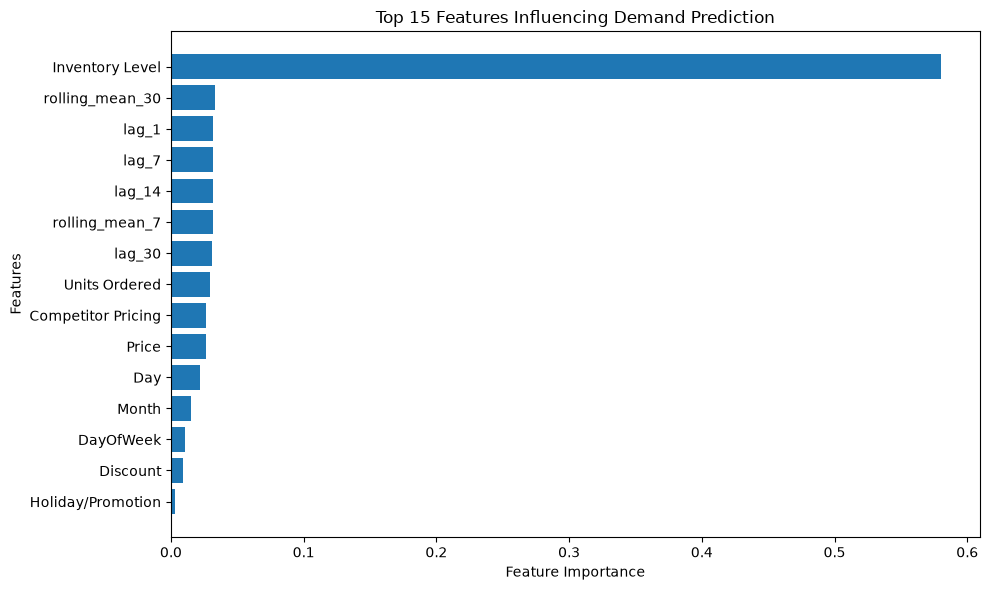

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES:")
display(importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(10, 6))

top_features = importance.head(15).sort_values(
    by='Importance'
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Demand Prediction")

plt.tight_layout()
plt.show()


CORRELATION WITH UNITS SOLD:


Units Sold            1.000000
Demand Forecast       0.996859
Inventory Level       0.590004
rolling_mean_30       0.004709
Day                   0.003187
Discount              0.002994
Competitor Pricing    0.001518
Price                 0.001318
lag_7                 0.001266
lag_1                 0.000049
DayOfWeek            -0.000120
Month                -0.000222
rolling_mean_7       -0.000542
Holiday/Promotion    -0.001108
Units Ordered        -0.001162
Year                 -0.003241
IsWeekend            -0.004201
lag_14               -0.004622
lag_30               -0.006420
Name: Units Sold, dtype: float64

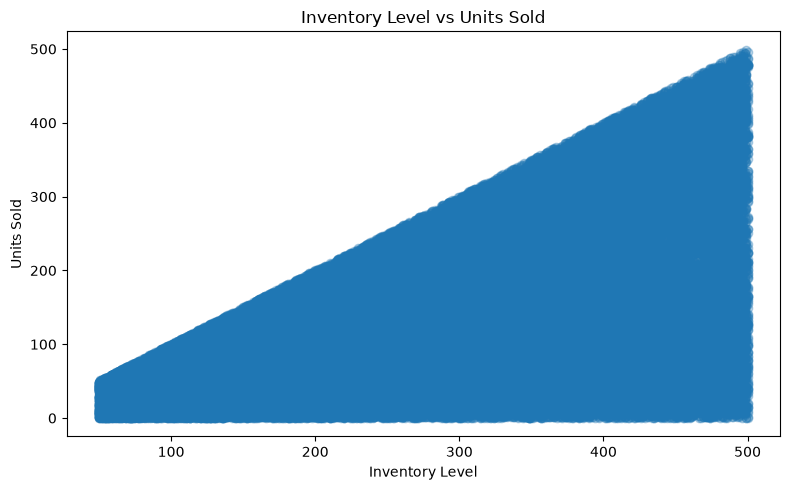

In [17]:

# Check correlation between numerical variables and Units Sold

correlations = df.corr(numeric_only=True)['Units Sold'].sort_values(
    ascending=False
)

print("CORRELATION WITH UNITS SOLD:")
display(correlations)

# Visualize inventory level vs actual sales
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Inventory Level'],
    df['Units Sold'],
    alpha=0.3
)

plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")
plt.title("Inventory Level vs Units Sold")

plt.tight_layout()
plt.show()


In [18]:

# Check whether each product has consistent categories
print("CATEGORIES PER PRODUCT:")
print(
    df.groupby('Product ID')['Category'].nunique()
)

# Check whether each product has consistent regions
print("\nREGIONS PER PRODUCT:")
print(
    df.groupby('Product ID')['Region'].nunique()
)

# Check how much sales vary over time
print("\nDAILY SALES STATISTICS:")
print(
    df.groupby('Date')['Units Sold'].sum().describe()
)

# Check average sales for each category
print("\nAVERAGE SALES BY CATEGORY:")
print(
    df.groupby('Category')['Units Sold'].mean().sort_values(
        ascending=False
    )
)



CATEGORIES PER PRODUCT:
Product ID
P0001    5
P0002    5
P0003    5
P0004    5
P0005    5
P0006    5
P0007    5
P0008    5
P0009    5
P0010    5
P0011    5
P0012    5
P0013    5
P0014    5
P0015    5
P0016    5
P0017    5
P0018    5
P0019    5
P0020    5
Name: Category, dtype: int64

REGIONS PER PRODUCT:
Product ID
P0001    4
P0002    4
P0003    4
P0004    4
P0005    4
P0006    4
P0007    4
P0008    4
P0009    4
P0010    4
P0011    4
P0012    4
P0013    4
P0014    4
P0015    4
P0016    4
P0017    4
P0018    4
P0019    4
P0020    4
Name: Region, dtype: int64

DAILY SALES STATISTICS:
count      701.000000
mean     13650.258203
std       1030.860332
min      10642.000000
25%      12982.000000
50%      13667.000000
75%      14326.000000
max      17239.000000
Name: Units Sold, dtype: float64

AVERAGE SALES BY CATEGORY:
Category
Furniture      137.742936
Groceries      137.062803
Clothing       136.709230
Toys           136.079843
Electronics    134.897401
Name: Units Sold, dtype: float64


In [19]:

# Check category consistency for each product
category_check = df.groupby('Product ID')['Category'].nunique()

print("Products with more than one category:",
      (category_check > 1).sum())

print("\nCategory count for each product:")
display(category_check)

# Check region consistency
region_check = df.groupby('Product ID')['Region'].nunique()

print("\nRegions per product:")
display(region_check)

# Check average daily sales variation
daily_sales = df.groupby('Date')['Units Sold'].sum()

print("\nDAILY SALES SUMMARY:")
print(daily_sales.describe())

# Check average sales by category
print("\nAVERAGE SALES BY CATEGORY:")
display(
    df.groupby('Category')['Units Sold']
    .mean()
    .sort_values(ascending=False)
)


Products with more than one category: 20

Category count for each product:


Product ID
P0001    5
P0002    5
P0003    5
P0004    5
P0005    5
P0006    5
P0007    5
P0008    5
P0009    5
P0010    5
P0011    5
P0012    5
P0013    5
P0014    5
P0015    5
P0016    5
P0017    5
P0018    5
P0019    5
P0020    5
Name: Category, dtype: int64


Regions per product:


Product ID
P0001    4
P0002    4
P0003    4
P0004    4
P0005    4
P0006    4
P0007    4
P0008    4
P0009    4
P0010    4
P0011    4
P0012    4
P0013    4
P0014    4
P0015    4
P0016    4
P0017    4
P0018    4
P0019    4
P0020    4
Name: Region, dtype: int64


DAILY SALES SUMMARY:
count      701.000000
mean     13650.258203
std       1030.860332
min      10642.000000
25%      12982.000000
50%      13667.000000
75%      14326.000000
max      17239.000000
Name: Units Sold, dtype: float64

AVERAGE SALES BY CATEGORY:


Category
Furniture      137.742936
Groceries      137.062803
Clothing       136.709230
Toys           136.079843
Electronics    134.897401
Name: Units Sold, dtype: float64

In [20]:

# Compare actual sales and existing demand forecast

df['Forecast Difference'] = (
    df['Demand Forecast'] - df['Units Sold']
)

print("FORECAST DIFFERENCE STATISTICS:")
display(df['Forecast Difference'].describe())

print("\nFIRST 10 COMPARISONS:")
display(
    df[['Units Sold', 'Demand Forecast', 'Forecast Difference']].head(10)
)

print("\nCORRELATION:")
print(
    df['Units Sold'].corr(df['Demand Forecast'])
)


FORECAST DIFFERENCE STATISTICS:


count    70100.000000
mean         5.028891
std          8.661387
min        -10.000000
25%         -2.480000
50%          5.000000
75%         12.500000
max         20.000000
Name: Forecast Difference, dtype: float64


FIRST 10 COMPARISONS:


,Units Sold,Demand Forecast,Forecast Difference
0,200,212.24,12.24
1,13,17.12,4.12
2,104,101.35,-2.65
3,230,220.16,-9.84
4,105,98.38,-6.62
5,159,154.91,-4.09
6,212,221.77,9.77
7,61,72.93,11.93
8,12,16.07,4.07
9,106,105.13,-0.87



CORRELATION:
0.996858884689903


In [21]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Simple baseline: predict today's sales using previous day's sales
baseline_predictions = X_test['lag_1']

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("BASELINE MODEL RESULTS")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))

print("\nMODEL COMPARISON")
print("Baseline MAE:", round(baseline_mae, 2))
print("Random Forest MAE:", round(rf_mae, 2))
print("XGBoost MAE:", round(xgb_mae, 2))


BASELINE MODEL RESULTS
MAE: 119.58
RMSE: 153.18

MODEL COMPARISON
Baseline MAE: 119.58
Random Forest MAE: 68.93
XGBoost MAE: 69.0


In [22]:

# Train Random Forest without Inventory Level

X_train_no_inventory = X_train.drop(
    columns=['Inventory Level']
)

X_test_no_inventory = X_test.drop(
    columns=['Inventory Level']
)

rf_without_inventory = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_without_inventory.fit(
    X_train_no_inventory,
    y_train
)

predictions_no_inventory = rf_without_inventory.predict(
    X_test_no_inventory
)

mae_no_inventory = mean_absolute_error(
    y_test,
    predictions_no_inventory
)

rmse_no_inventory = np.sqrt(
    mean_squared_error(y_test, predictions_no_inventory)
)

print("RANDOM FOREST WITHOUT INVENTORY LEVEL")
print("MAE:", round(mae_no_inventory, 2))
print("RMSE:", round(rmse_no_inventory, 2))


RANDOM FOREST WITHOUT INVENTORY LEVEL
MAE: 88.87
RMSE: 108.23


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Shape: (913000, 4)

Columns:
Index(['date', 'store', 'item', 'sales'], dtype='str')

Data Types:
date       str
store    int64
item     int64
sales    int64
dtype: object


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB


In [6]:
df.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [9]:
df["date"] = pd.to_datetime(df["date"])

print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2013-01-01 00:00:00
End Date: 2017-12-31 00:00:00


In [10]:
print("Stores:", df["store"].nunique())
print("Items:", df["item"].nunique())

Stores: 10
Items: 50


In [13]:
sales_by_store = df.groupby("store")["sales"].sum().sort_values(ascending=False)

print(sales_by_store)

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64


In [15]:
sales_by_item = df.groupby("item")["sales"].sum().sort_values(ascending=False)

print(sales_by_item.head(10))

item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
Name: sales, dtype: int64
